# ENG4200 Coursework 1 
### 2687140P - Alicja Potoniec

In [23]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import tracemalloc

import platform, sklearn
from sklearn.model_selection import GridSearchCV, learning_curve, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
# To fix sklearn warnings when finding no strokes. Building custom precision scorer.
from sklearn.metrics import make_scorer, precision_score, recall_score, classification_report, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

#==== HARDWARE DETAILS
cpu = [l for l in open('/proc/cpuinfo') if 'model name' in l][0].split(':')[1].strip()
ram = os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1e9
print(cpu, '|', os.cpu_count(), 'threads |', round(ram, 1), 'GB RAM')

#==== PACKAGE VERSIONS
print(platform.platform(), '|Python', platform.python_version(), '|sklearn', sklearn.__version__)

#ensuring I can pick and choose to save figures and keep high resolution
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi']=150

data_raw = pd.read_csv('stroke-prediction.csv')

print(data_raw.info())
display(data_raw.head())

AMD Ryzen 7 5800H with Radeon Graphics | 16 threads | 29.3 GB RAM
Linux-7.0.9-76070009-generic-x86_64-with-glibc2.39 |Python 3.12.3 |sklearn 1.9.1
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB
None


,id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


# Exploration

In [24]:
# Some BMI data is missing, 201 entries. 

#======== Checking the number of strokes vs no stroke data========

stroke_total = data_raw['stroke'].value_counts()
print(f"Stroke cases in full data: {stroke_total[1]}")

# Ther % of the strokes in respect to the full data.
print(f"Stroke %: {data_raw['stroke'].mean():.2%}")

# Stroke data is very small in comparison to the full set. Check how much of the stroke data has no BMI.
stroke_noBMI = data_raw[data_raw['bmi'].isnull()]['stroke'].value_counts()
print(f"stroke cases with no BMI data: {stroke_noBMI[1]}")

# % of stroke cases with no BMI data.
print(f"stroke cases with no BMI: {stroke_noBMI[1] / stroke_total[1]:.2%}")

Stroke cases in full data: 249
Stroke %: 4.87%
stroke cases with no BMI data: 40
stroke cases with no BMI: 16.06%


Mean BMI for full dataset: 28.89
median BMI for full datet: 28.10


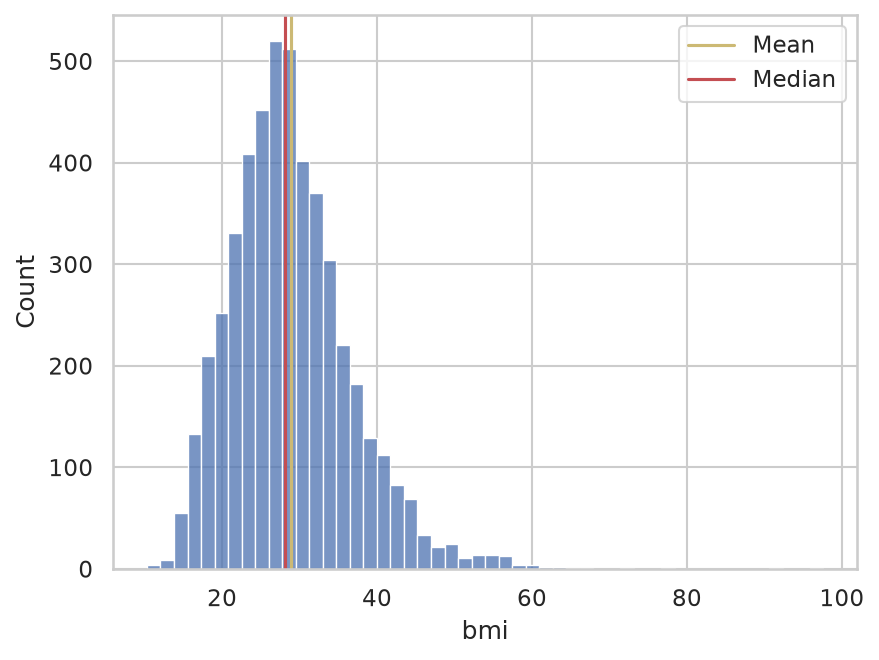

BMI skew: 1.06


In [25]:
# 16% of the total of stroke cases have missing BMI data.
# Disregarding the entries without the BMI data would remove too many stroke cases from the analysis. 
# Instead, the missing BMI values will be replaced with either the total mean or median BMI.
# the data for the BMI will be assessed for skewness to justify the choice.

#---Calculating the mean BMI---
meanBMI = data_raw['bmi'].mean()
print(f'Mean BMI for full dataset: {meanBMI:.2f}')

#---Calculating the median BMI---
medianBMI = data_raw['bmi'].median()
print(f'median BMI for full datet: {medianBMI:.2f}')

#---PLOTTING---
sns.histplot(data_raw['bmi'], bins=50)
plt.axvline(data_raw['bmi'].mean(), color='y', label='Mean')
plt.axvline(data_raw['bmi'].median(), color='r', label='Median')
plt.legend()

plt.show()

#===PANDAS BUILT IN SKEW FUNCTION===
print(f"BMI skew: {data_raw['bmi'].skew():.2f}")



In [26]:
# Taken from the above analysis, the BMI data is positively skewed. Therefore, will be using the median to populate the missing BMI values.

# There are BMI values which aren't visible on the graph, so for visualisation and proof of skewed data, these largest values will be printed below.
print((data_raw['bmi']>63).sum())
print(data_raw['bmi'].nlargest(10).to_string())
#This largest bmi data is what skewes the mean value. 

# ---Populate & drop ID numbers (not needed in the analysis)--- 
data = data_raw.fillna({'bmi' : medianBMI}).drop(columns='id')

#==== Checking if the BMI data populated successsfully ====

print(data.isna().sum())
print(data.columns.tolist())


8
2128    97.6
4209    92.0
928     78.0
544     71.9
1559    66.8
358     64.8
4188    64.4
2764    63.3
3825    61.6
2840    61.2
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


In [27]:
#==== Checking the remaining category columns which contain strings ====

cat_cols = ['gender', 'ever_married', 'work_type', 'residence_type', 'smoking_status']

for col in cat_cols:
    print(data[col].value_counts().to_string())
    print()



gender
Female    2994
Male      2115
Other        1

ever_married
Yes    3353
No     1757

work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22

residence_type
Urban    2596
Rural    2514

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789



In [28]:
# ===== Assessing the imbalance in the categorical data. ======

# Gender = Other
print(f"F/M gender against the 'other': {data[data['gender']=='Other']['stroke'].to_string()}")
print(f"===confirmed that the 'Other' gender has no stroke cases, so it will be removed from further analysis===\n")

# Smoking status = Unknown
num_cols = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'stroke']

for col in cat_cols:
    if col == 'smoking_status':
        continue
    print(pd.crosstab(data['smoking_status'], data[col], normalize='index'))
    print()

print(data.groupby('smoking_status')[num_cols].mean().to_string() + "\n")
# Unknown smoking status will be kept as its own category. 
# It makes up of 30% of the data and it is not random. Many of the unknown patients are younger, or are children. 
# Dropping this amount of data would lose 30% and populating this would invent smoking histories for children. 

#---- Dropping the single 'Other' gender entry ----
data = data[data['gender'] != 'Other'].copy()
print(f"New data shape after dropping 'Other': {data.shape[0]}")
print(data['gender'].value_counts().to_string() + "\n")

print(data['smoking_status'].value_counts().to_string())


F/M gender against the 'other': 3116    0
===confirmed that the 'Other' gender has no stroke cases, so it will be removed from further analysis===

gender             Female      Male    Other
smoking_status                              
Unknown          0.541451  0.458549  0.00000
formerly smoked  0.538983  0.459887  0.00113
never smoked     0.649577  0.350423  0.00000
smokes           0.572877  0.427123  0.00000

ever_married           No       Yes
smoking_status                     
Unknown          0.583549  0.416451
formerly smoked  0.166102  0.833898
never smoked     0.280127  0.719873
smokes           0.226869  0.773131

work_type        Govt_job  Never_worked   Private  Self-employed  children
smoking_status                                                            
Unknown          0.079016      0.005181  0.414508       0.101036  0.400259
formerly smoked  0.150282      0.000000  0.600000       0.235028  0.014689
never smoked     0.149049      0.007400  0.640063       0.174947

In [29]:
# ====== Erroneous Value Checks ======

# 1 - Range Check
print(data[num_cols].describe().loc[['count', 'min', 'max']].T.round(2))

# 2 - Binary Columns
for col in['hypertension', 'heart_disease', 'stroke']:
    print(col, sorted(data[col].unique().tolist()))

# 3 - non-integer age
age_decimal = data[data['age'] %1 != 0] ['age']
print(f"non-integer ages: {len(age_decimal)}, max: {age_decimal.max()}")
print(sorted(age_decimal.unique().tolist()))

#========= Explanation ==========
# the binary columns behave as expected. 
# floats in ages are acceptable, these represent months in young children. 
#
#
# Worth a check on how the different age bands get affected by strokes.
# Likely will still keep the young bands as these are still patients.
# age group bins are chosen based on a paper from UK Health Security Agency. Choice is based on trends within the age groups. 
# pd.cut includes the left edge and excludes the right edge. 
# The age group data is as follows:
# <1, 1-4, 5-8, 9-17, 18-33, 34-50, 51-67, 68-89
age_bands = pd.cut(data['age'], bins=[0, 1, 5, 9, 18, 34, 51, 68, 90], right=False)
print(data.groupby(age_bands, observed = True)['stroke'].agg(['count', 'sum', 'mean']))

# surprising to learn that 1-4 age group has recorded 1 stroke, similarily with the sroke in 9-17.
# All patients will be included in the model to avoid any future bias.


                    count    min     max
age                5109.0   0.08   82.00
hypertension       5109.0   0.00    1.00
heart_disease      5109.0   0.00    1.00
avg_glucose_level  5109.0  55.12  271.74
bmi                5109.0  10.30   97.60
stroke             5109.0   0.00    1.00
hypertension [0, 1]
heart_disease [0, 1]
stroke [0, 1]
non-integer ages: 115, max: 1.88
[0.08, 0.16, 0.24, 0.32, 0.4, 0.48, 0.56, 0.64, 0.72, 0.8, 0.88, 1.08, 1.16, 1.24, 1.32, 1.4, 1.48, 1.56, 1.64, 1.72, 1.8, 1.88]
          count  sum      mean
age                           
[0, 1)       43    0  0.000000
[1, 5)      212    1  0.004717
[5, 9)      179    0  0.000000
[9, 18)     422    1  0.002370
[18, 34)    920    1  0.001087
[34, 51)   1206   20  0.016584
[51, 68)   1271   77  0.060582
[68, 90)    856  149  0.174065


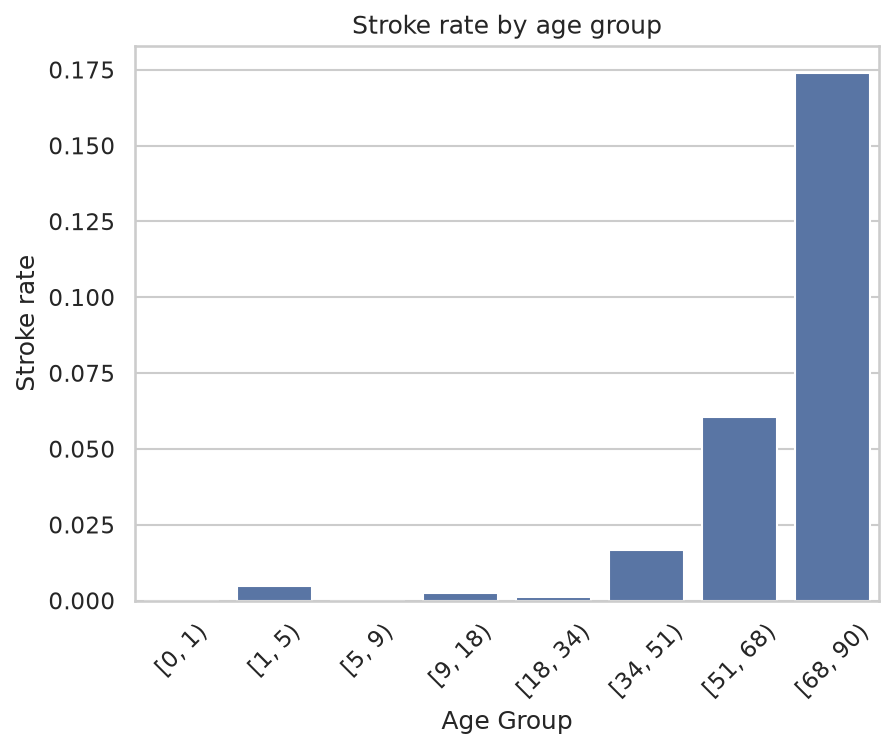

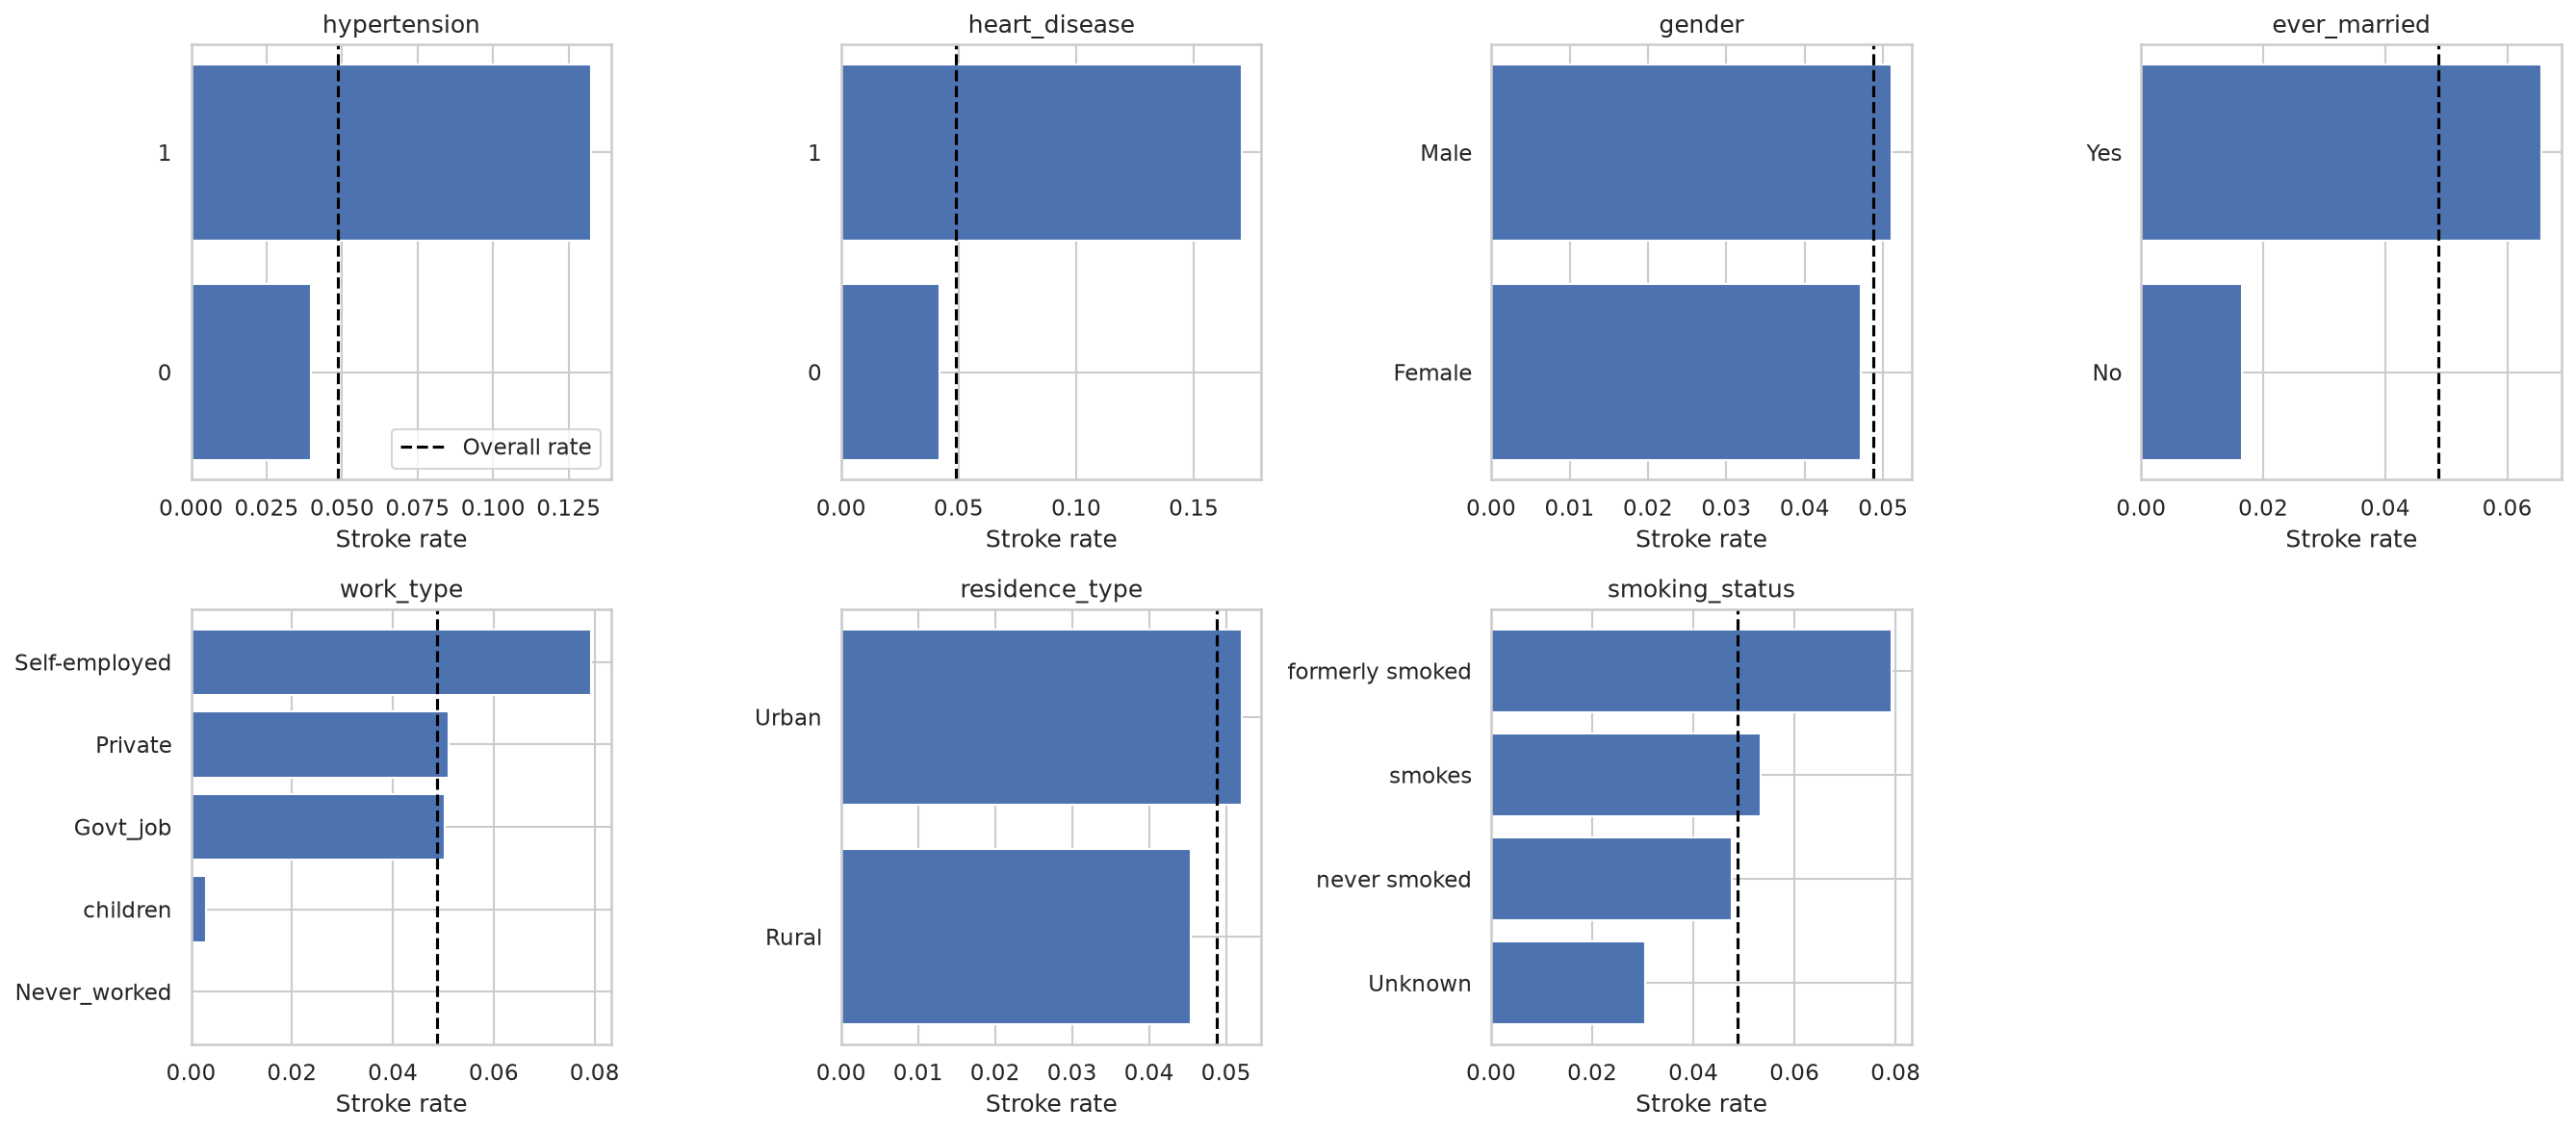

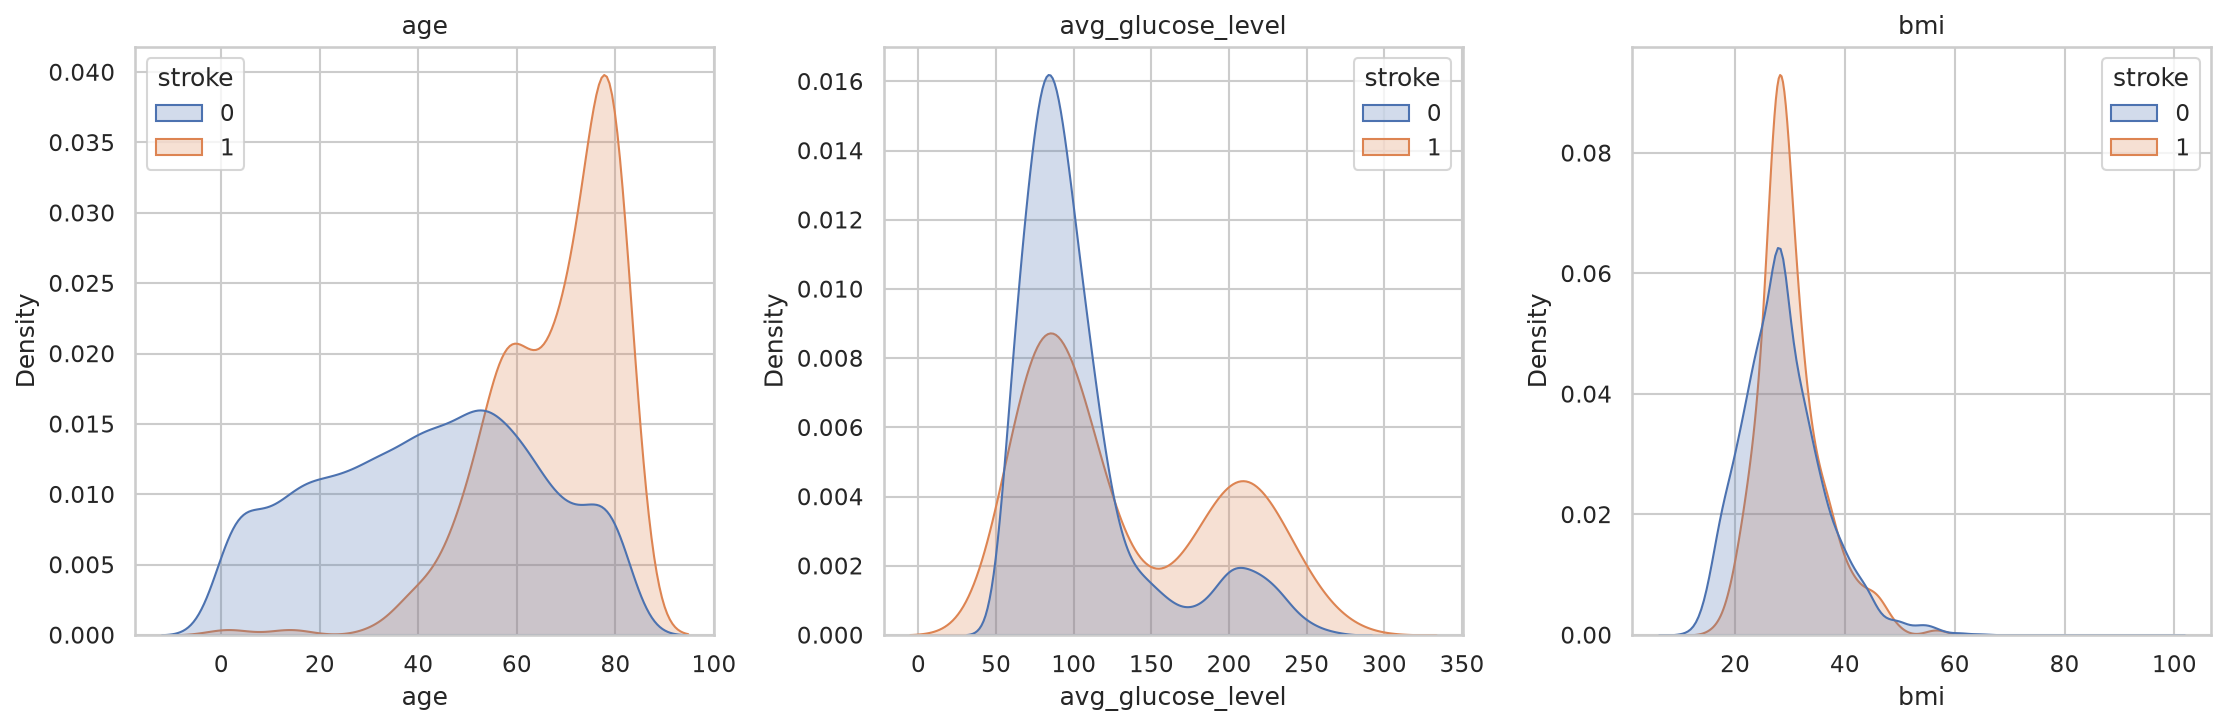

In [30]:
#==========PLOTTING==========

# ----Stroke rate per age group (UKHSA age bands)
sns.barplot(x=age_bands, y=data['stroke'], errorbar=None)
plt.xlabel('Age Group')
plt.ylabel('Stroke rate')
plt.title('Stroke rate by age group')
plt.xticks(rotation=45)
plt.show()

# ----Stroke rate within each cat
rate_cols = ['hypertension', 'heart_disease']+ cat_cols
overall_rate = data['stroke'].mean()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, col in zip(axes, rate_cols):
    rates = data.groupby(col)['stroke'].mean().sort_values()
    ax.barh(rates.index.astype(str), rates.values)
    ax.axvline(overall_rate, color='black', linestyle='--', label='Overall rate')
    ax.set_title(col)
    ax.set_xlabel('Stroke rate')
axes[0].legend()
axes[-1].axis('off')
plt.tight_layout()
plt.show()

#-----Numerical data distribution plots
fig, axes=plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ['age', 'avg_glucose_level', 'bmi']):
    sns.kdeplot(data=data, x=col, hue='stroke', common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


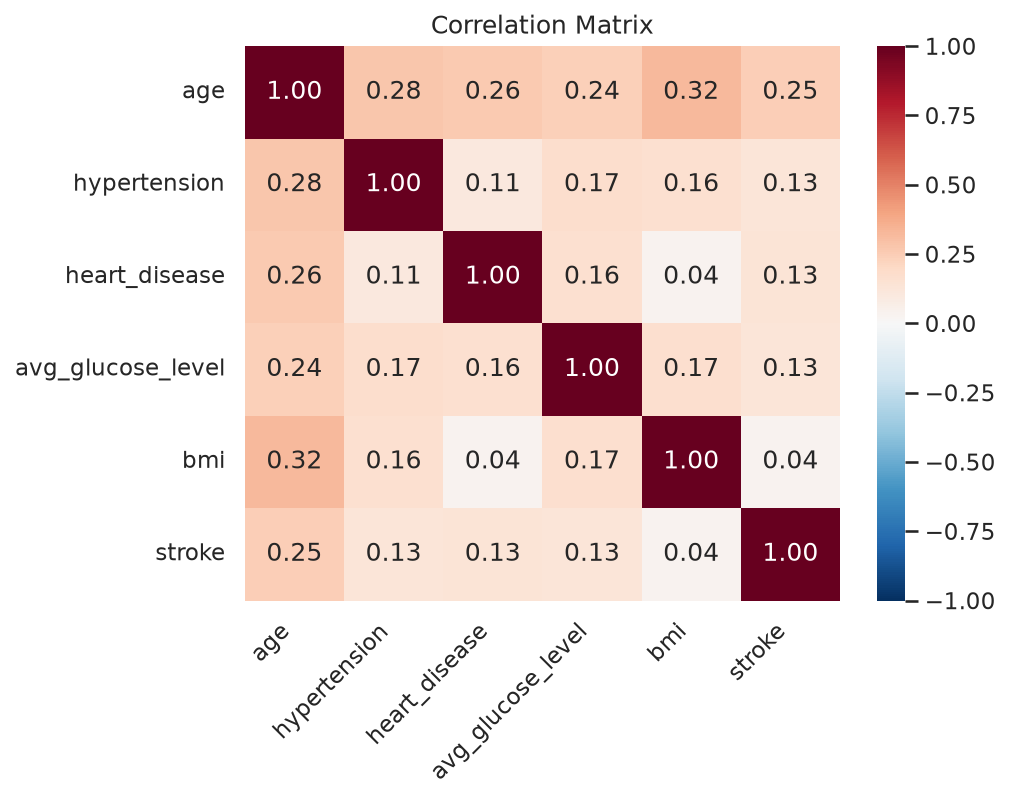

In [31]:
#======== FINDING CORRELATION ========
# Correlation between numeric features.

sns.heatmap(data[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.xticks(rotation=45, ha='right')
plt.show()

No pair of numeric features is strongly correlated (maximum 0.32, age and BMI), so collinearity is not a problem and all features are kept. Age has the strongest link with stroke (0.25), which is expected.

# Model

In [32]:
# ==== Preparing data ====
# Starting from raw data - Everything else will be fixed via the pipeline
# Median of training rows only

data_model = data_raw.drop(columns='id') 
data_model = data_model[data_model['gender'] != 'Other'].copy()

# X - features (clues = every other feature but stroke), Y - target (the answer = stroke column)
X = data_model.drop(columns='stroke')
y = data_model['stroke']

# 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=8, stratify=y)

print(f"train: {X_train.shape}, Test: {X_test.shape}")
print(f"Stroke share - train: {y_train.mean(): .2%} test: {y_test.mean():.2%}")
print(f"Missing BMI - train: {X_train['bmi'].isna().sum()}, test: {X_test['bmi'].isna().sum()}")

train: (4087, 10), Test: (1022, 10)
Stroke share - train:  4.87% test: 4.89%
Missing BMI - train: 158, test: 43


In [33]:
#======== PIPELINE ========
# Pipeline Build
# Filling missing BMI with median - scale
# Encoding text features - learning from trained rows only

#----Numerical features, no stroke
# reusing cat_cols from data exploration
num_features = ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']

# Mini pipeline
# SimpleImputer - filling missing gaps with the median
# StandardScaler - Rescales coefficients for fair comparison. Each column to mean 0 and spread 1. Ex: so glucose doesn't dominate age.
# handle_unknown=ignore, a category never seen in training is set to all 0 to let the model continue.
preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])
pipe = Pipeline([('prep', preprocess),
                 ('model', LogisticRegression(max_iter = 3000))])
pipe.fit(X_train, y_train)

print(preprocess.get_feature_names_out())

['num__age' 'num__hypertension' 'num__heart_disease'
 'num__avg_glucose_level' 'num__bmi' 'cat__gender_Female'
 'cat__gender_Male' 'cat__ever_married_No' 'cat__ever_married_Yes'
 'cat__work_type_Govt_job' 'cat__work_type_Never_worked'
 'cat__work_type_Private' 'cat__work_type_Self-employed'
 'cat__work_type_children' 'cat__residence_type_Rural'
 'cat__residence_type_Urban' 'cat__smoking_status_Unknown'
 'cat__smoking_status_formerly smoked' 'cat__smoking_status_never smoked'
 'cat__smoking_status_smokes']


the mini-pipeline above is fitted and working. 
There are 5 numeric features and 15 text categories. cat_smoking_status_Uknown confirms that the decision to keep the unknown is successfully built in.

In [34]:
#======== BASELINE MODEL ========
# CROSS VALIDATION ON TRAINING ROWS
#
# Majority Baseline: the score of always predicting 'no stroke'
majority = 1 - y_train.mean()
print(f"Always predicting 'no stroke': {majority:.2%} accuracy\n")

# 5 folds, each keeping identical stroke share 4.87% of strokes kept in every fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=8)  # number 8 kept throughout for reproducibility.

scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'recall', 'f1'])

for metric in ['accuracy', 'recall', 'f1']:
    s = scores['test_'+ metric]
    print(f"{metric}: {s.mean():.3f} +/- {s.std():.3f}")


Always predicting 'no stroke': 95.13% accuracy

accuracy: 0.951 +/- 0.001
recall: 0.005 +/- 0.010
f1: 0.010 +/- 0.020


The model's accuracy is the same as the "always no stroke" assumption.
Bad results are expected. Always assuming that there's no stroke gives the model a 95.13% accuracy.
Recall is the share of real stroke patients that the model managed to find: 0.005 +/- 0.010, about 1 in 200, which is really bad.
F1 balances recall and precision (harmonic mean). Its low score (0.010) shows the model almost never predicts a stroke.
The data has a large imbalance due to the small percentage of strokes (4.87%).
Predicting "no" for every patient is the easiest way to be accurate.

In [35]:
#======== BALANCED CLASS WEIGHTS ========
# Same pipeline but with class_weight='balanced'
# Each stroke rate is given a higher count.
# Reduce bias by forcing the model to account for the minority.
#

pipe_balanced = Pipeline([('prep', preprocess),
                          ('model', LogisticRegression(max_iter=3000, class_weight='balanced'))])
experiments = {'baseline': pipe, 'balanced': pipe_balanced}

#----CUSTOM PRECISION SCORER
# zero_division=0 - if a fold predicts no strokes, precision 0/0 is set to 0 instead of a warning.
metrics = {'accuracy': 'accuracy',
           'precision': make_scorer(precision_score, zero_division=0),
           'recall': 'recall',
           'f1': 'f1'}

rows = []
for name, model in experiments.items():
    s = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics)
    row = {'experiment': name}
    for m in metrics:
        row[m] = s['test_'+ m].mean()
    row['fit time (s)'] = s['fit_time'].mean()
    rows.append(row)

print(pd.DataFrame(rows).round(3).to_string(index=False))

experiment  accuracy  precision  recall    f1  fit time (s)
  baseline     0.951      0.200   0.005 0.010         0.018
  balanced     0.739      0.133   0.789 0.228         0.016


The drop in accuracy is fine. A model saying "no" to everyone is useless even with a 95.13% accuracy. The 73.9% is fine, as at least now the model is finding strokes.
Precision shows that amongst the patients it flagged, 13.3% had a stroke, 2.7× the overall stroke rate of 4.87%.
F1 rose from 0.010 to 0.228, showing a much better balance between catching strokes and avoiding false alarms.
Recall rose from 0.005 to 0.789, showing that balancing the weights greatly improves the model at no extra computational cost  (fit times are almost identical, see the table above).

In [36]:
#======== TUNING REGULARISATION STRENGTH - C ========
# Overfitting penalty
# C=1 / penalty strength
# C<< simple model, may underfit
# C>> flexible, may overfit
# 7 values from 0.001 to 1000 5 folds
# F1 focus on balance.

grid = {'model__C': np.logspace(-3,3,7)}
search = GridSearchCV(pipe_balanced, grid, cv=cv, scoring='f1', return_train_score=True)
search.fit(X_train, y_train)
results = pd.DataFrame(search.cv_results_)[['param_model__C', 'mean_train_score', 'mean_test_score', 'std_test_score']]
print(results.round(3).to_string(index=False))
print(f"\nBest C: {search.best_params_['model__C']}, cross-validated F1: {search.best_score_:.3f}")
final = search.best_estimator_


 param_model__C  mean_train_score  mean_test_score  std_test_score
          0.001             0.238            0.233           0.015
          0.010             0.235            0.234           0.009
          0.100             0.238            0.230           0.008
          1.000             0.238            0.228           0.011
         10.000             0.238            0.228           0.010
        100.000             0.238            0.228           0.011
       1000.000             0.238            0.228           0.011

Best C: 0.01, cross-validated F1: 0.234


In [37]:
#======== TUNED MODEL, SAME METRICS AS THE EXPERIMENTS TABLE ========
s = cross_validate(final, X_train, y_train, cv=cv, scoring=metrics)
print({m: round(s['test_' + m].mean(), 3) for m in metrics})

{'accuracy': np.float64(0.737), 'precision': np.float64(0.137), 'recall': np.float64(0.824), 'f1': np.float64(0.234)}


Tuning C made very little difference: cross-validated F1 stayed between 0.228 and 0.234 for every C from 0.001 to 1000, and these differences are smaller than the spread between folds (std ≈ 0.01).
Training and validation F1 are almost identical at every C (0.238 vs 0.228–0.234), so the model is not overfitting, even with the weakest penalty. 
Logistic regression with 20 features is simple enough that regularisation has little to correct.
C = 0.01 scored highest (F1 = 0.234). 
As the scores are effectively tied, the stronger regularisation is a reasonable choice, since it gives the simpler model. 
With this tuning, the balanced model will be used going forward.

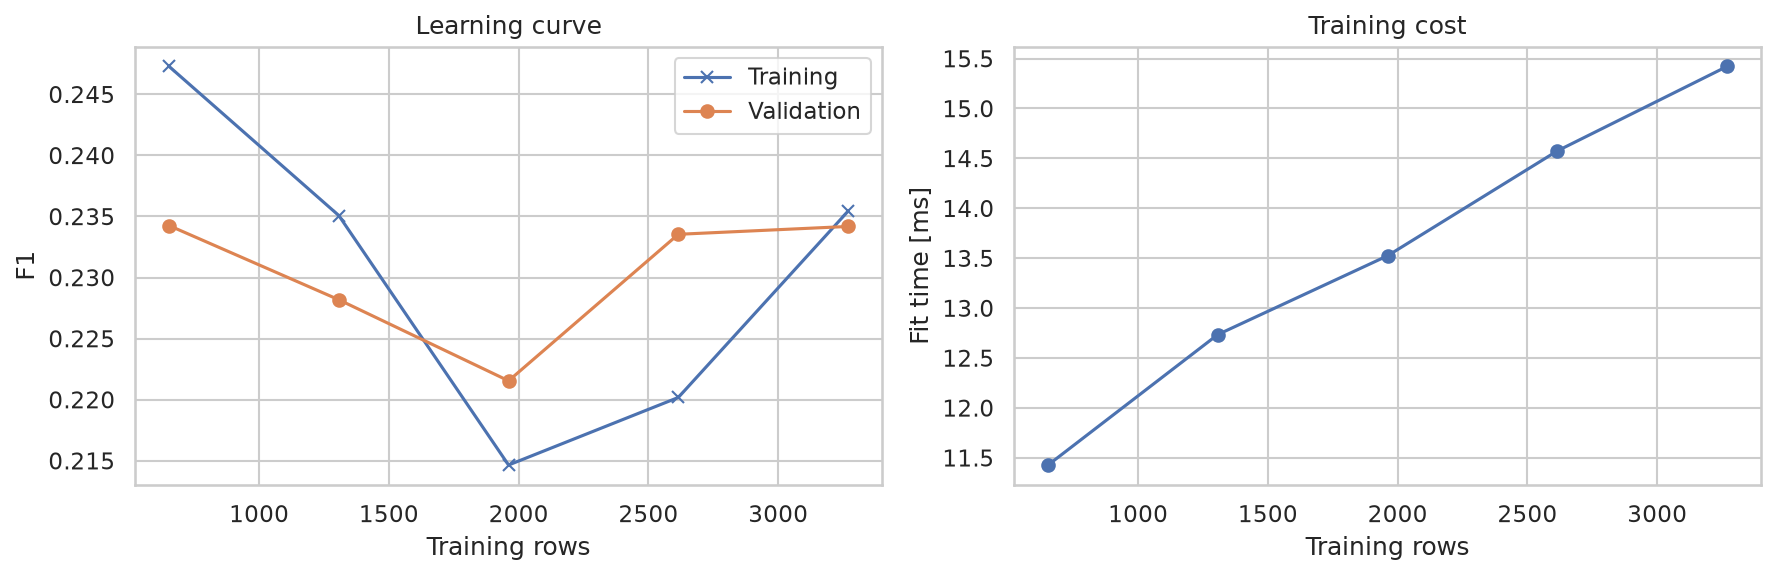

In [38]:
#======== LEARNING CURVE ========
# SCORE & FIT TIME VS TRAINING SIZE
# Model trained on 20%, 40%, 60%, 80%, 100% of the training rows
#
# would more data help?

sizes, train_scores, val_scores, fit_times, _ = learning_curve(
    final, X_train, y_train, cv=cv, scoring='f1',
    train_sizes=np.linspace(0.2, 1.0, 5), return_times=True
)
fig,(ax1, ax2) = plt.subplots(1,2, figsize=(12,4))

#Subplot 1 - training and value scores
ax1.plot(sizes, train_scores.mean(axis=1), 'x-', label='Training')
ax1.plot(sizes, val_scores.mean(axis=1), 'o-', label='Validation')
ax1.set_xlabel('Training rows')
ax1.set_ylabel('F1')
ax1.set_title('Learning curve')
ax1.legend()

#Subplot 2 - fitting times
ax2.plot(sizes, fit_times.mean(axis=1)*1000, 'o-')
ax2.set_xlabel('Training rows')
ax2.set_ylabel('Fit time [ms]')
ax2.set_title('Training cost')

plt.tight_layout()
plt.show()


F1 stays between about 0.215 and 0.247 at every training size. 
The y-axis is zoomed in, so the dip at around 2,000 rows is within fold-to-fold noise. 
At full size, training and validation F1 converge (≈0.235), confirming no overfitting. 
Validation F1 does not improve as more rows are added, more data is unlikely to help: performance is limited by the model (a linear decision boundary) and the available features rather than by the amount of data.
TTraining cost: fit time grows roughly linearly with training size and stays in the tens of milliseconds, so logistic regression is very cheap to train on this dataset.

 threshold  precision  recall  share flagged
       0.9      0.269   0.035          0.006
       0.8      0.217   0.226          0.051
       0.7      0.196   0.482          0.120
       0.6      0.160   0.683          0.208
       0.5      0.136   0.824          0.295
       0.4      0.109   0.884          0.394
       0.3      0.091   0.945          0.503
       0.2      0.077   0.985          0.624
       0.1      0.062   0.990          0.778


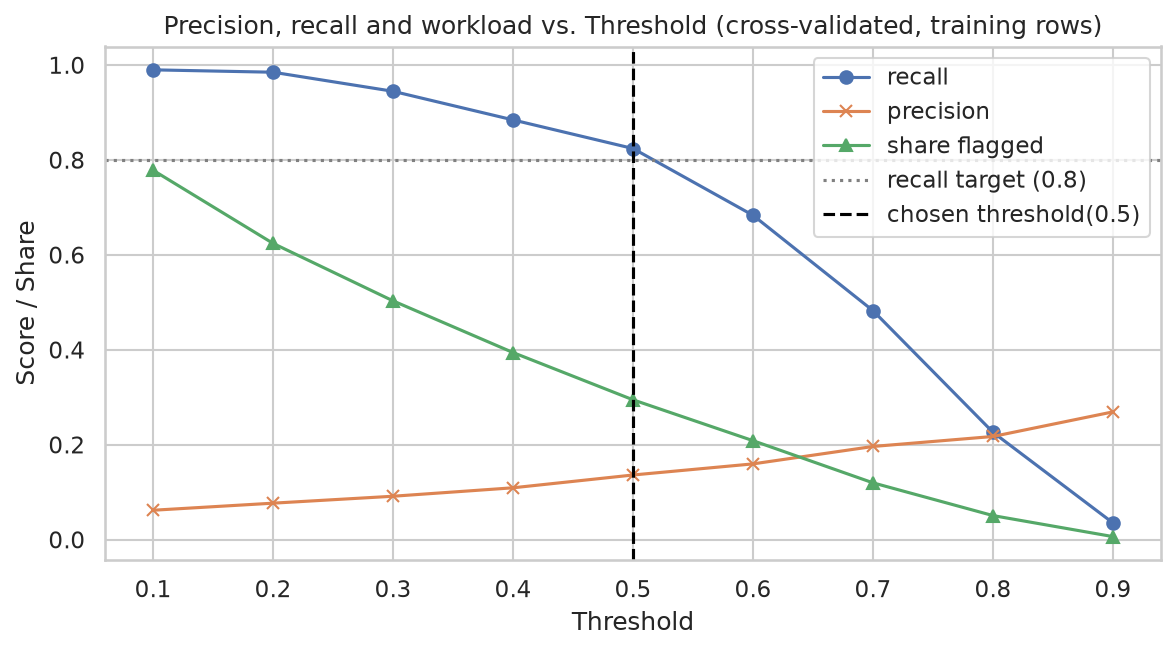

In [39]:
#======== DECISION THRESHOLD ========
# the treshold decides what counts as a stroke
# Probabilities are aquired from the cross-validation. the model with the above pipeline is used for this, test set isn'try
#
# cross_val_predict - gives back the prediction for every training row, each one made by a model that didn't train on that row.
# method='predict_proba' - gives the probabilities instead of 0/1, [:,1] gives two columns P(no stroke) and P(stroke), then selects one, the stroke probability.
# (proba >= t) True/False for each patient. Is the probability at or above the treshold?
# p.mean() shows a workload, how many people need the follow up check? Share of patients flagged by the treshold. 


prob = cross_val_predict(final, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

rows=[]
for t in [0.9,0.8,0.7,0.6,0.5,0.4,0.3,0.2,0.1]:
    p = (prob >= t).astype(int)
    rows.append({'threshold':t,
                'precision': precision_score(y_train, p, zero_division=0),
                'recall': recall_score(y_train, p),
                'share flagged': p.mean()})

print(pd.DataFrame(rows).round(3).to_string(index=False))

thresh_table = pd.DataFrame(rows)
THRESHOLD = 0.5

fig, ax = plt.subplots(figsize =(8, 4.5))
ax.plot(thresh_table['threshold'], thresh_table['recall'], 'o-', label = 'recall')
ax.plot(thresh_table['threshold'], thresh_table['precision'], 'x-', label = 'precision')
ax.plot(thresh_table['threshold'], thresh_table['share flagged'], '^-', label = 'share flagged')
ax.axhline(0.8, color='grey', linestyle=':', label = 'recall target (0.8)')
ax.axvline(THRESHOLD, color='black', linestyle='--', label=f'chosen threshold({THRESHOLD})')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score / Share')
ax.set_title('Precision, recall and workload vs. Threshold (cross-validated, training rows)')
ax.legend()
plt.tight_layout()
plt.show()

In the above the model that was used is the class_weight = 'balanced', the resulting values above are shifted upwards so are not a true representation of real-world probabilities. It's only purpose is to choose a cut-off threshold, not to determine the patient's chance of a stroke. 

Picking a threshold of 0.5 as it flags the lowest share of patients (29.5%) amond thresholds with a recall of 0.824. As it can be seen from the graph, to raise precision just by a tiny amount introduces exponential penalty in both recall and the share of flagged stroke cases. Therefore picking 0.5 threshold value was the right decision to make. 

0.5 is the default threshold choice. the above supports that the default cut-off is the sensible choice for this dataset.
At a threshold of 0.5 the model caught 36 out of 50 strokes with ROC-AUC score of 0.826.
About 1 in 7.5 flagged patients had a stroke, the recall=0.72, precision=0.13 and F1=0.22.

              precision    recall  f1-score   support

   no stroke       0.98      0.76      0.86       972
      stroke       0.13      0.72      0.22        50

    accuracy                           0.76      1022
   macro avg       0.56      0.74      0.54      1022
weighted avg       0.94      0.76      0.82      1022

Fit time: 18.9 ms | Prediction time (1022 patients): 5.3 ms | Peak memory during fit: 1.61 MB
            fit time(ms)  predict time(ms)  peak memory (MB)
unweighted         21.83              5.44              1.61
final              18.75              5.23              1.61


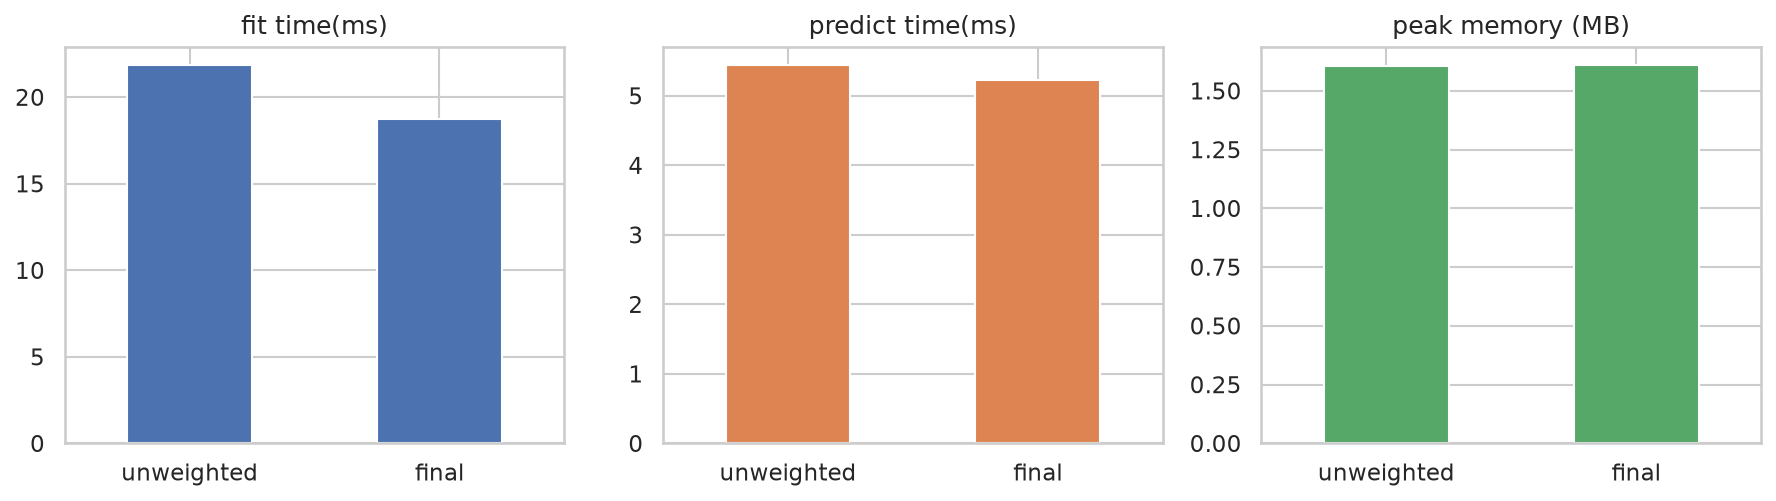

In [40]:
#======== TEST SET: FINAL MODEL, TIMING AND MEMORY ========
# tracemalloc - built in Python tool for tracking memory resources used to compute. peak memory keeps the peaks in usage to throw away 'current' background value.
# time.perf_counter used for a precise stopwatch for timing fit and prediction.


THRESHOLD = 0.5

#Fit time measured on its own, no tracemalloc here as it's slowing down the performance, skewing the analysis
start = time.perf_counter()
final.fit(X_train, y_train)
fit_time = time.perf_counter()-start

# Peak memory, measured as a separate fit
tracemalloc.start()
final.fit(X_train, y_train)
_, peak_memory = tracemalloc.get_traced_memory()
tracemalloc.stop()

# Predict on test rows and timing.
start = time.perf_counter()
prob_test = final.predict_proba(X_test)[:,1]
predict_t = time.perf_counter()-start
pred_test = (prob_test >= THRESHOLD).astype(int)

print(classification_report(y_test, pred_test, target_names=['no stroke', 'stroke'], zero_division=0))
print(f"Fit time: {fit_time*1000:.1f} ms | Prediction time ({len(X_test)} patients): {predict_t*1000:.1f} ms | Peak memory during fit: {peak_memory/1e6:.2f} MB")

#======= COMPARISON OF COMPUTATIONAL COST BETWEEN UNWEIGHTED & FINAL MODEL ========

def measure_cost(model):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_t = time.perf_counter() - start

    tracemalloc.start()
    model.fit(X_train, y_train)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    start = time.perf_counter()
    model.predict_proba(X_test)
    pred_t = time.perf_counter() - start

    return{'fit time(ms)':fit_t*1000, 'predict time(ms)':pred_t*1000, 'peak memory (MB)': peak/1e6}

cost = pd.DataFrame({'unweighted':measure_cost(pipe), 'final':measure_cost(final)}).T
print(cost.round(2))

cost.plot.bar(subplots=True, layout=(1,3), figsize=(12, 3.5), legend=False, rot=0)
plt.tight_layout()
plt.show()



Fitting on 4087 rows takes tens of milliseconds, predicting 1022 patients takes a few milliseconds, and peak Python memory during fitting is under 2 MB. Exact values are printed above and vary between runs and machines.

As seen on the bar charts. The effect of a computing a weighted model does not have any significant effects on any of the computational factors. 

# Evaluation

ROC-AUC (test): 0.826


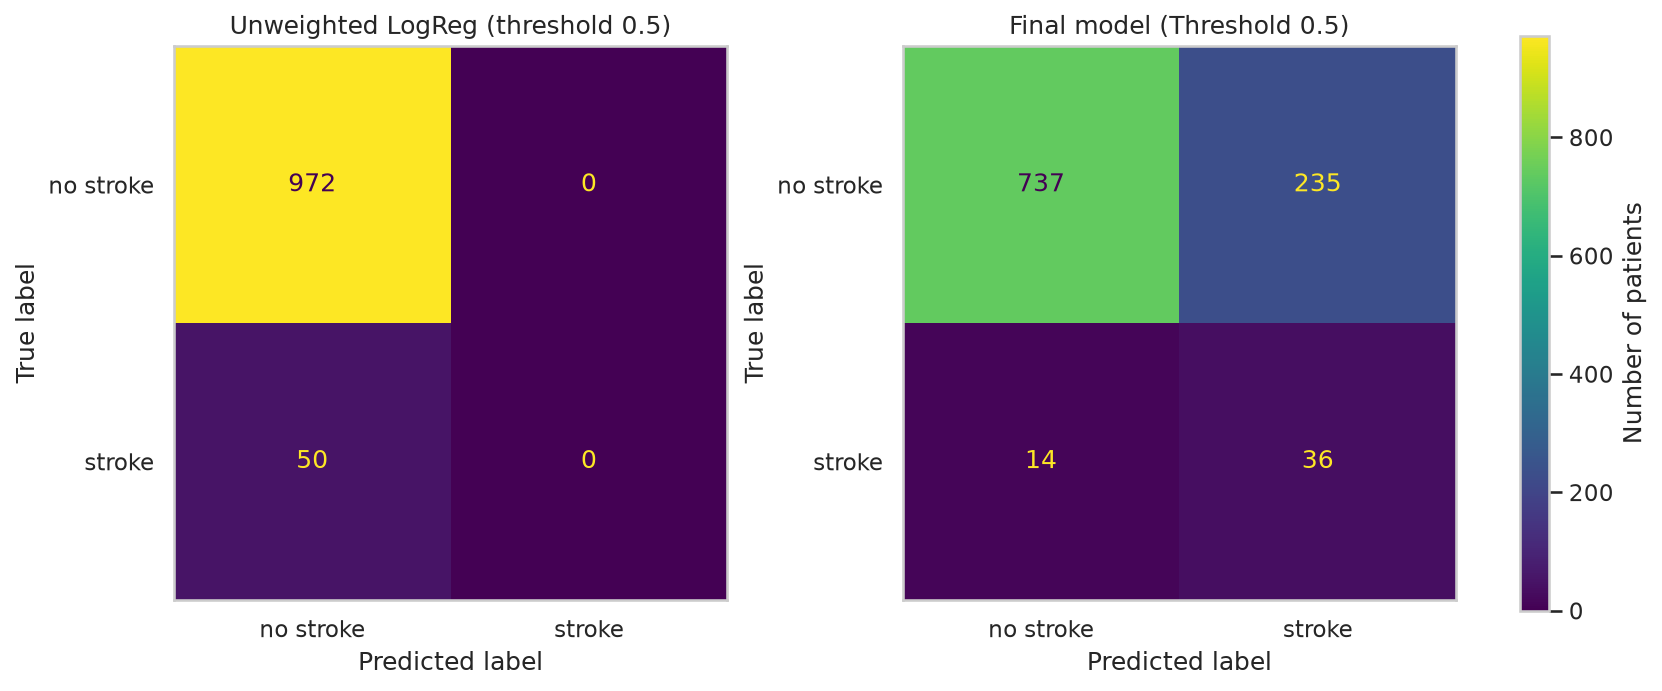

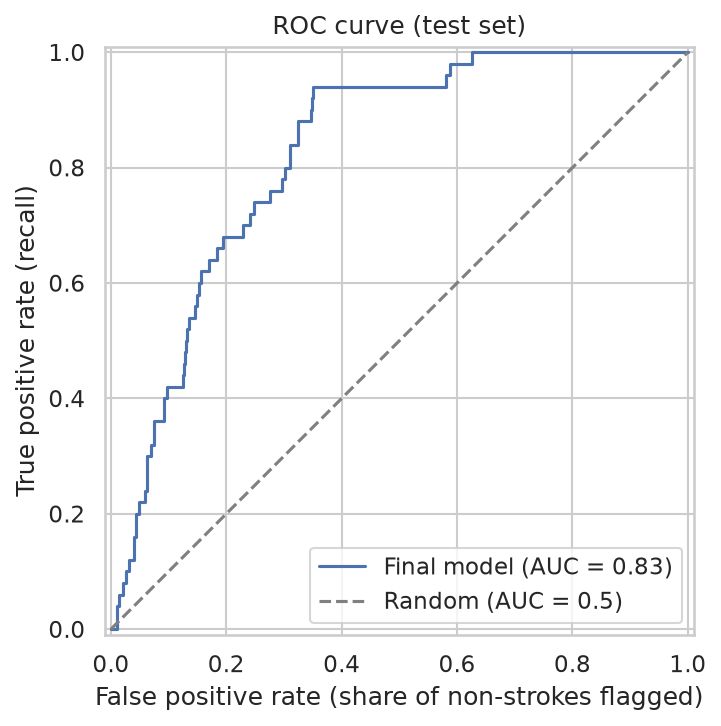

In [41]:
# ---- ROC-AUC - the classification equivalent to R^2
# Overall model score
print(f"ROC-AUC (test): {roc_auc_score(y_test, prob_test):.3f}")

#==== TEST RESULTS: UNWEIGHTED VS FINAL MODEL ====
# Unweighted model was rejected by the cv, used here only for comparison reasons. 

fig, axes = plt.subplots(1,2, figsize=(11, 4.5), layout='constrained')
labels = ['no stroke', 'stroke']
models = [pipe.predict(X_test), pred_test]
titles = ['Unweighted LogReg (threshold 0.5)', f'Final model (Threshold {THRESHOLD})']
for ax, preds, title in zip(axes, models, titles):
    disp = ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=labels, ax=ax, colorbar=False, cmap='viridis', im_kw={'vmin':0, 'vmax':(y_test==0).sum()})
    ax.set_title(title)
    ax.grid(False)
fig.colorbar(disp.im_, ax=axes, label='Number of patients')
plt.show()

#==== ROC CURVE - TEST SET ====
fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_predictions(y_test, prob_test, ax=ax, name='Final model')
ax.plot([0, 1], [0, 1], '--', color='grey', label='Random (AUC = 0.5)')
ax.set_xlabel('False positive rate (share of non-strokes flagged)')
ax.set_ylabel('True positive rate (recall)')
ax.set_title('ROC curve (test set)')
ax.legend()
plt.tight_layout()
plt.show()



The model ranks stroke patients well. With the ROC-AUC score of 0.826 being fairly decent for a young model (0.5 score is no better than flipping a coin and 1.0 being very good at prediction).

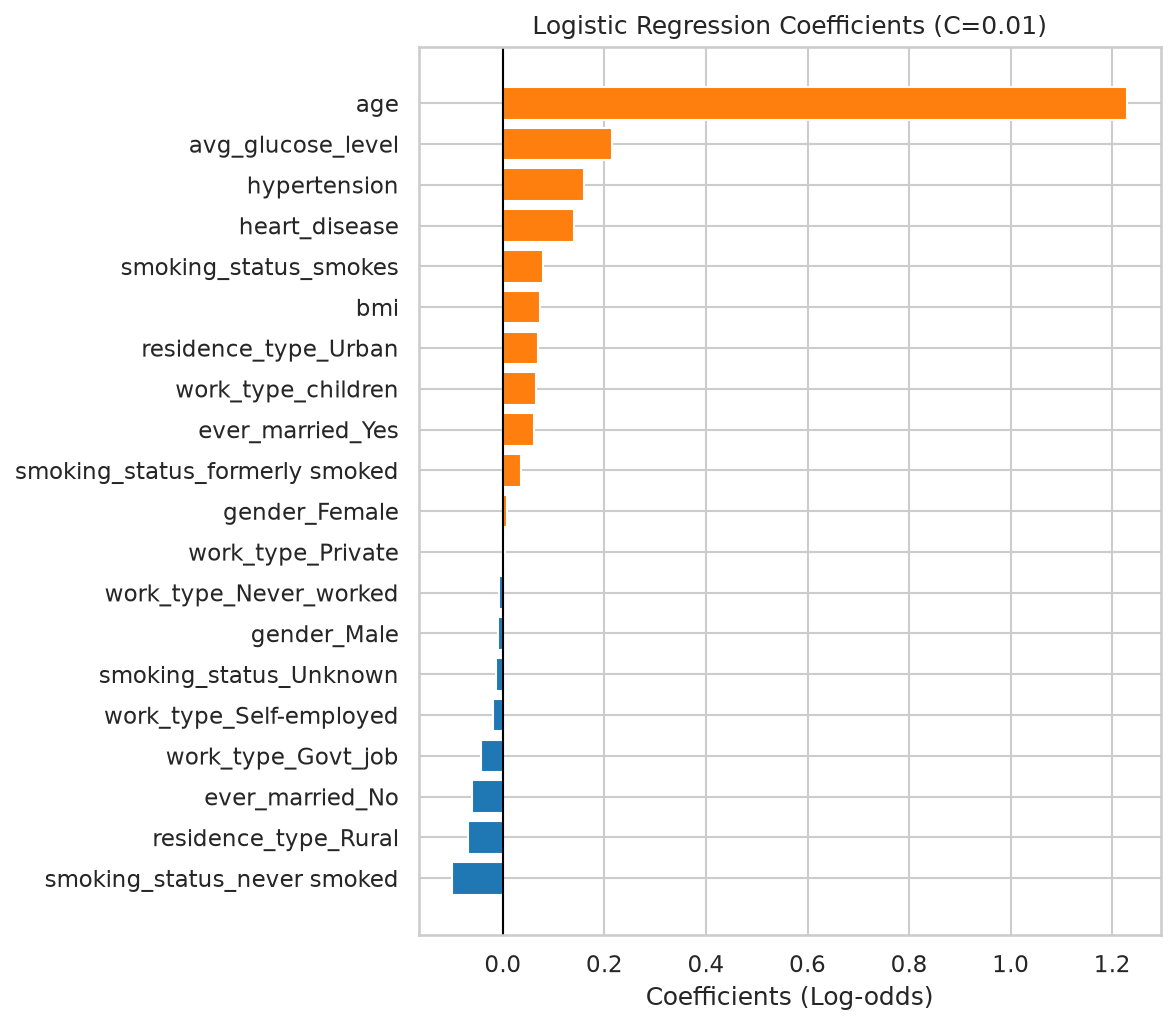

In [42]:
# ===== FINAL EXPLORATION =====
# Exploring which features drive the prediction
# positive = raising risk of stroke prediction
# negative = lowering the risk of stroke prediction
#
# As per SD and to make the coefficients comparable, the numerical values are scaled. 

coefs = final.named_steps['model'].coef_[0]
names = final.named_steps['prep'].get_feature_names_out()

coef_table = pd.Series(coefs, index=names).sort_values()
coef_table.index = coef_table.index.str.replace('num__','').str.replace('cat__','')

plt.figure(figsize=(8,7))
colours = ['tab:orange' if v>0 else 'tab:blue' for v in coef_table.values]
plt.barh(coef_table.index, coef_table.values, color=colours)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Coefficients (Log-odds)')
plt.title(f"Logistic Regression Coefficients (C={final.named_steps['model'].C})")
plt.tight_layout()
plt.show()

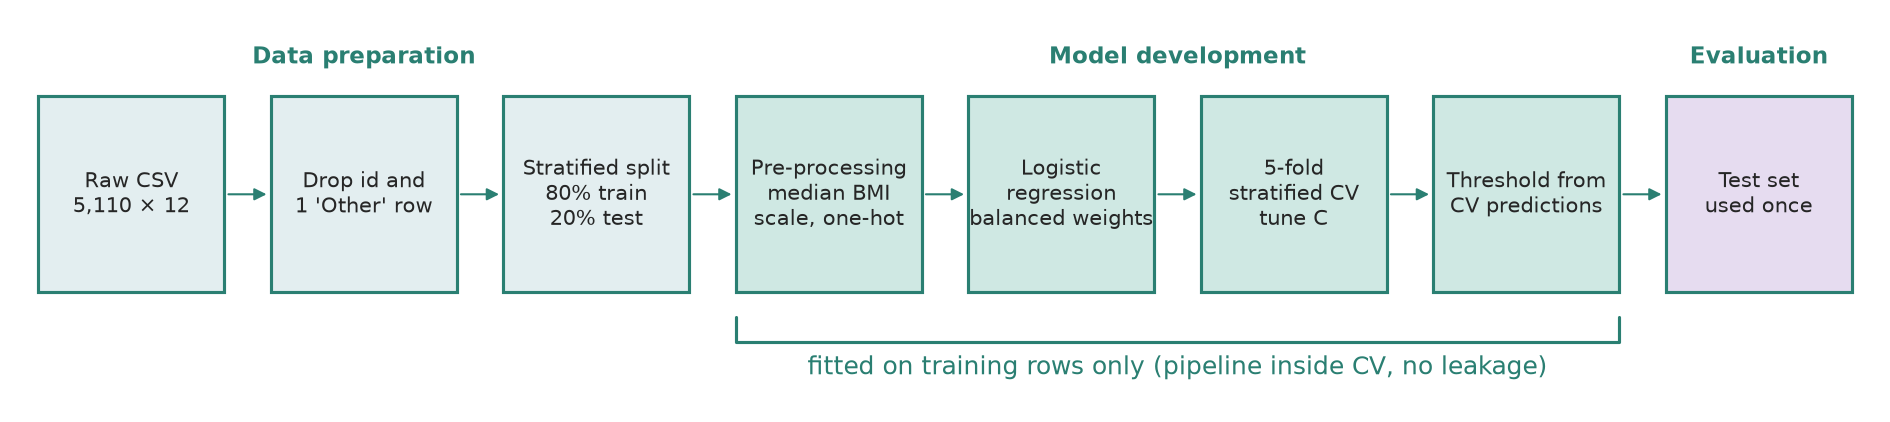

In [43]:
#======== PIPELINE DIAGRAM ========

steps = [('Raw CSV\n5,110 × 12', 'data'),
         ("Drop id and\n1 'Other' row", 'data'),
         ('Stratified split\n80% train\n20% test', 'data'),
         ('Pre-processing\nmedian BMI\nscale, one-hot', 'train'),
         ('Logistic\nregression\nbalanced weights', 'train'),
         ('5-fold\nstratified CV\ntune C', 'train'),
         ('Threshold from\nCV predictions', 'train'),
         ('Test set\nused once', 'test')]
colours = {'data': '#e3eef0', 'train': '#cfe8e3', 'test': '#e6dcf0'}
accent = '#2a7f72'

fig, ax = plt.subplots(figsize=(16, 3.4))

for i, (text, kind) in enumerate(steps):
    x = i * 2
    ax.add_patch(plt.Rectangle((x, 0), 1.6, 1.2, facecolor=colours[kind], edgecolor=accent, linewidth=1.5))
    ax.text(x + 0.8, 0.6, text, ha='center', va='center', fontsize=10)
    if i < len(steps) - 1:
        ax.annotate('', xy=(x + 2, 0.6), xytext=(x + 1.6, 0.6),
                    arrowprops=dict(arrowstyle='-|>', color=accent))

# Stage labels above the boxes
ax.text(2.8, 1.4, 'Data preparation', ha='center', fontsize=11, fontweight='bold', color=accent)
ax.text(9.8, 1.4, 'Model development', ha='center', fontsize=11, fontweight='bold', color=accent)
ax.text(14.8, 1.4, 'Evaluation', ha='center', fontsize=11, fontweight='bold', color=accent)

# Bracket under the steps that only ever see training rows (boxes 4-7)
ax.plot([6, 6, 13.6, 13.6], [-0.15, -0.3, -0.3, -0.15], color=accent)
ax.text(9.8, -0.5, 'fitted on training rows only (pipeline inside CV, no leakage)',
        ha='center', color=accent)

ax.set_xlim(-0.2, 15.8)
ax.set_ylim(-0.7, 1.7)
ax.axis('off')
plt.show()